# Trabalho 2 — Classificador de veículo de imprensa e componente contemporâneo (embeddings + sumarização)

**Disciplina:** Processamento de Linguagem Natural  **Autora:** Isabella Oliveira Marcelli

**Continuação do Trabalho 1** (*Framing do conflito Israel–Palestina na imprensa*). No T1 descrevemos o vocabulário de cada
veículo (adjetivos por lado, bigramas, similaridade de cosseno). Agora transformamos essa pergunta em **uma aplicação
de classificação supervisionada**:

> **Dado o texto de uma matéria sobre o conflito, é possível prever de qual veículo (ou grupo de veículos) ela veio?
> E o que o classificador aprendeu — estilo editorial, tema ou vocabulário de enquadramento?**

Se um modelo simples consegue separar veículos *sem ver o nome do veículo*, existe uma "assinatura lexical" editorial. Os
pesos do modelo nos mostram **quais termos** compõem essa assinatura — é a ponte com a análise de *framing* do T1.

**Estrutura (segue o enunciado):**

| Etapa | Conteúdo |
|---|---|
| 1 | Corpus: origem, classes, viés e limitações |
| 2 | Processamento: limpeza, normalização, tokenização, lematização, stopwords, representação (BoW / TF-IDF) |
| 3 | Modelo principal: classificação (TF-IDF + Regressão Logística) |
| 4 | Avaliação: CV repetida, hold-out + GridSearch, métricas por classe, ROC-AUC/AP, matriz de confusão, erros, baselines, vazamento |
| Compl. | Agrupamento (K-Means/LSA), busca textual, tom por lado (VADER), agência por dependências |
| 5 | Visualizações (14, nas etapas acima) |
| 6 | Componente contemporâneo (**só no final**): embeddings contextuais, RAG com FLAN-T5 e sumarização (Hugging Face) |

> O componente generativo/pré-treinado **não substitui** as etapas tradicionais: ele entra por último e é *comparado* com o
> modelo tradicional.

## 0. Ambiente e bibliotecas

In [7]:
import sys, subprocess, importlib.util

EM_COLAB = "google.colab" in sys.modules
if EM_COLAB:  # no Colab instalamos o que falta; localmente use: pip install -r requirements.txt
    faltam = [p for p, m in [("spacy", "spacy"), ("sentence-transformers", "sentence_transformers"),
                              ("transformers", "transformers")] if importlib.util.find_spec(m) is None]
    if faltam:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltam], check=True)

import json, re, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spacy

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import (confusion_matrix, classification_report, ConfusionMatrixDisplay)
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
PALETA = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#7F7F7F", "#F0E442"]

RES = Path("resultados"); FIG = RES / "figuras"
FIG.mkdir(parents=True, exist_ok=True)

def salvar(nome):
    plt.tight_layout(); plt.savefig(FIG / f"{nome}.png", dpi=150, bbox_inches="tight")

print("spaCy", spacy.__version__, "| Colab:", EM_COLAB)

spaCy 3.8.18 | Colab: True


## Etapa 1 — Corpus

### 1.1 Origem
O corpus é o **mesmo construído no Trabalho 1**: matérias sobre o conflito Israel–Palestina coletadas pela **NewsAPI**
(plano gratuito, janela de ~1 mês em set/2026, busca por palavras-chave no título/descrição, filtrada por domínio).
O texto completo foi extraído com `trafilatura`, traduzido para inglês quando necessário e limpo com regex (Notebook 02 do T1).
O arquivo de entrada é o `corpus_limpo.csv` (coluna `texto_limpo`).

**Acesso aos dados:** o notebook procura `corpus_limpo.csv` (1) no Google Drive (Colab) ou (2) em `data/`. Se não encontrar,
usa um **corpus público de contingência** (20 Newsgroups, 4 categorias) *apenas* para que o código continue executável —
nesse caso os resultados **não** dizem respeito ao tema do trabalho (o notebook avisa).

In [8]:
def localizar_corpus():
    if EM_COLAB:
        from google.colab import drive
        drive.mount("/content/drive")
        achados = list(Path("/content/drive/MyDrive").rglob("corpus_limpo.csv"))
        if achados:
            return achados[0]
    for c in [Path("data/corpus_limpo.csv"), Path("../data/corpus_limpo.csv"), Path("corpus_limpo.csv")]:
        if c.exists():
            return c
    return None

caminho = localizar_corpus()
if caminho is not None:
    df = pd.read_csv(caminho)
    df = df[df["texto_limpo"].notna()].reset_index(drop=True)
    FONTE = "corpus T1"
    print("Corpus do T1 carregado de:", caminho)
else:
    from sklearn.datasets import fetch_20newsgroups
    cats = ["talk.politics.mideast", "sci.space", "rec.sport.hockey", "soc.religion.christian"]
    d = fetch_20newsgroups(subset="all", categories=cats, remove=("headers", "footers", "quotes"))
    df = pd.DataFrame({"id": range(len(d.data)), "texto_limpo": d.data,
                       "veiculo": [d.target_names[i] for i in d.target]})
    df["grupo"] = df["veiculo"]; df["titulo"] = df["texto_limpo"].str[:80]
    df = df[df["texto_limpo"].str.split().str.len() > 50].reset_index(drop=True)
    FONTE = "CONTINGENCIA (20 Newsgroups) - NAO e o corpus do trabalho"
    print("ATENCAO:", FONTE)

print("Fonte:", FONTE, "| artigos:", len(df))
df[["id", "grupo", "veiculo", "titulo"]].head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Corpus do T1 carregado de: /content/drive/MyDrive/corpus_limpo.csv
Fonte: corpus T1 | artigos: 114


,id,grupo,veiculo,titulo
0,e0e82ff53fd8,eua,Fox News,Israel captures top Hamas commander in Gaza st...
1,1d727eecb74d,eua,Fox News,Michael Rapaport slams 'clown' Macklemore for ...
2,23a65a20479a,eua,Fox News,Pink hits back amid backlash for criticizing M...
3,dafd76bb38a0,eua,Fox News,'Nobody Wants This' star accuses Israel of 'ge...
4,f93c52db4e15,eua,Fox News,"Abdul El-Sayed hits back at Israel questions, ..."


### 1.2 Definição do problema e das classes
- **Alvo principal (`ALVO`)**: `veiculo` (classificação multiclasse).
- **Alvo secundário**: `grupo` (EUA / Oriente Médio / Ásia Oriental), que tem mais exemplos por classe.
- Classes com menos de `MIN_POR_CLASSE` artigos são removidas, pois não permitem validação cruzada estratificada
  (decisão registrada e discutida no relatório).

In [9]:
ALVO = "veiculo"
MIN_POR_CLASSE = 4   # no corpus do T1: Jerusalem Post tem 4 artigos (mantido); Straits Times tem 1 (removido)

df["num_palavras"] = df["texto_limpo"].str.split().str.len()
contagem_inicial = df[ALVO].value_counts()
print("Distribuição ANTES do filtro:\n", contagem_inicial, "\n")

validas = contagem_inicial[contagem_inicial >= MIN_POR_CLASSE].index
removidas = contagem_inicial[contagem_inicial < MIN_POR_CLASSE]
if len(removidas):
    print("Classes removidas (< %d artigos):" % MIN_POR_CLASSE, {k: int(v) for k, v in removidas.items()})
df = df[df[ALVO].isin(validas)].reset_index(drop=True)

contagem = df[ALVO].value_counts()
razao = contagem.max() / contagem.min()
print(f"\nClasses mantidas: {len(contagem)} | artigos: {len(df)} | razão maior/menor classe: {razao:.1f}x")
assert len(contagem) >= 2, "Menos de 2 classes após o filtro: reduza MIN_POR_CLASSE ou use ALVO='grupo'."

resumo_classes = (df.groupby(ALVO)["num_palavras"].agg(artigos="count", palavras_total="sum", palavras_mediana="median")
                  .sort_values("artigos", ascending=False))
resumo_classes

Distribuição ANTES do filtro:
 veiculo
Channel News Asia    50
Al Jazeera           38
CNN                  11
Fox News             10
Jerusalem Post        4
Straits Times         1
Name: count, dtype: int64 

Classes removidas (< 4 artigos): {'Straits Times': 1}

Classes mantidas: 5 | artigos: 113 | razão maior/menor classe: 12.5x


,artigos,palavras_total,palavras_mediana
veiculo,,,
Channel News Asia,50,31609,608.0
Al Jazeera,38,20946,521.0
CNN,11,16326,1139.0
Fox News,10,8415,608.5
Jerusalem Post,4,2134,446.0


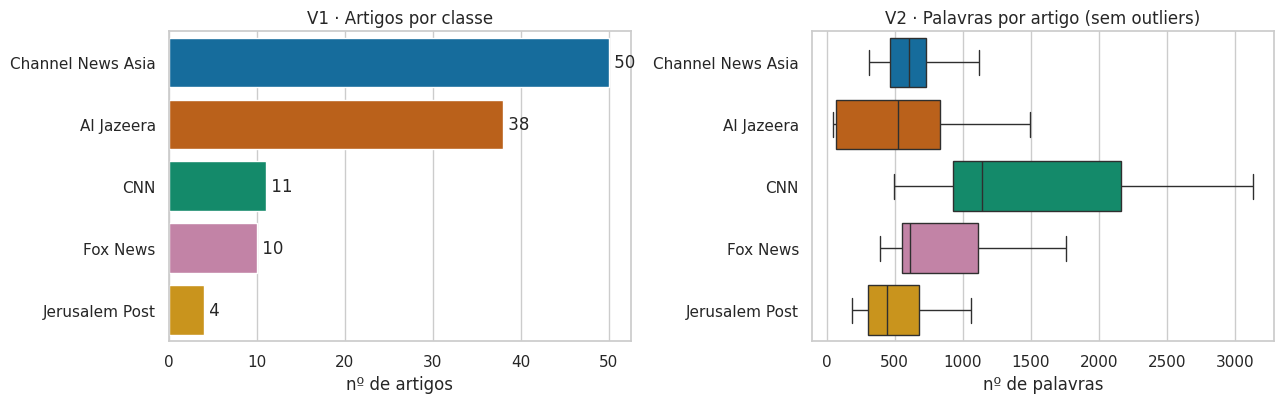

In [10]:
# VISUALIZAÇÃO 1 — distribuição das classes
# VISUALIZAÇÃO 2 — tamanho dos textos por classe (importante: volume desigual pode virar atalho do modelo)
ordem = contagem.index.tolist()
cor = {c: PALETA[i % len(PALETA)] for i, c in enumerate(ordem)}

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
sns.barplot(x=contagem.values, y=ordem, palette=[cor[c] for c in ordem], ax=ax[0])
for i, v in enumerate(contagem.values): ax[0].text(v, i, f" {v}", va="center")
ax[0].set_title("V1 · Artigos por classe"); ax[0].set_xlabel("nº de artigos"); ax[0].set_ylabel("")
sns.boxplot(data=df, x="num_palavras", y=ALVO, order=ordem, palette=cor, ax=ax[1], showfliers=False)
ax[1].set_title("V2 · Palavras por artigo (sem outliers)"); ax[1].set_xlabel("nº de palavras"); ax[1].set_ylabel("")
salvar("v1_v2_classes_e_tamanho"); plt.show()

### 1.3 Viés e limitações do corpus (resumo — detalhado no relatório)
1. **Amostra pequena e desbalanceada** (herdada do T1): poucos artigos por veículo e volumes muito diferentes. Métricas têm alta variância; por isso usamos validação cruzada repetida e reportamos desvio-padrão.
2. **Viés de seleção da NewsAPI**: só indexa parte dos artigos de cada domínio; a busca por palavras-chave no título/descrição favorece matérias *diretamente* sobre o conflito e pode perder cobertura indireta.
3. **Janela curta (~1 mês)**: eventos específicos do período dominam o vocabulário (tema confunde-se com veículo).
4. **Tradução automática**: o grupo Brasil foi perdido no T1 por falhas de tradução; os textos traduzidos (se houver) têm estilo diferente dos originais em inglês — risco de o modelo aprender "foi traduzido".
5. **Atalhos (*data leakage*)**: nome do veículo, assinaturas, créditos de agência (AP, Reuters) e *datelines* permitem acertar sem olhar o enquadramento → **mascaramos** esses elementos e medimos a diferença (seção 4.5).
6. **Textos duplicados/agência**: a mesma matéria de agência pode aparecer em veículos diferentes, contaminando treino/teste.
7. **Classificar o veículo ≠ medir enquadramento**: acertar o veículo mostra *diferença de estilo/vocabulário*, não que o enquadramento seja "tendencioso". É um indício a ser interpretado, não um veredito.

## Etapa 2 — Processamento

Pipeline: **limpeza** (já feita por regex no T1; aqui só uma auditoria e mascaramento de atalhos) → **normalização** →
**tokenização** → **lematização** → **stopwords** → **representação** (BoW e TF-IDF).

In [11]:
# 2.1 Mascaramento de atalhos que identificam o veículo (evita vazamento de rótulo)
NOMES_VEICULOS = [
    r"al[\s\-]?jazeera", r"anadolu(?:\s+agency)?", r"\baa\.com\.tr", r"jerusalem\s+post", r"\bjpost(?:\.com)?",
    r"fox\s+news(?:\s+digital)?", r"\bfox\b", r"\bcnn\b", r"associated\s+press", r"\bap\s+news\b", r"\(ap\)", r"\bap\b",
    r"channel\s+news\s*asia", r"\bcna\b", r"straits\s+times", r"south\s+china\s+morning\s+post", r"\bscmp\b",
    r"\buol\b", r"metr[óo]poles", r"\bterra\b", r"\breuters\b", r"\bafp\b",
]
RE_VEICULOS = re.compile("|".join(NOMES_VEICULOS), flags=re.I)

def normalizar(t):
    t = t.replace("“", '"').replace("”", '"').replace("‘", "'").replace("’", "'")
    t = re.sub(r"[–—]+", "-", t)
    t = re.sub(r"<DATE>", " ", t)
    t = re.sub(r"\[ERRO DE TRADUCAO[^\]]*\]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

def mascarar(t):
    return re.sub(r"\s+", " ", RE_VEICULOS.sub(" ", t)).strip()

df["texto_norm"] = df["texto_limpo"].apply(normalizar)
df["texto_masc"] = df["texto_norm"].apply(mascarar)
mencoes = df["texto_norm"].apply(lambda t: len(RE_VEICULOS.findall(t)))
print(f"Artigos que citam algum nome de veículo/agência: {(mencoes > 0).sum()} de {len(df)} "
      f"({100 * (mencoes > 0).mean():.0f}%) | total de menções removidas no texto mascarado: {mencoes.sum()}")

Artigos que citam algum nome de veículo/agência: 53 de 113 (47%) | total de menções removidas no texto mascarado: 118


In [12]:
# 2.2 Tokenização + lematização + stopwords (spaCy). Cada versão do texto gera uma coluna de lemas.
try:
    nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])
except OSError:
    import spacy.cli; spacy.cli.download("en_core_web_sm")
    nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])

def lematizar(textos):
    saida = []
    for doc in nlp.pipe(textos, batch_size=16):
        saida.append(" ".join(t.lemma_.lower() for t in doc if t.is_alpha and not t.is_stop and len(t) > 1))
    return saida

df["lemas_bruto"] = lematizar(df["texto_norm"].tolist())   # com nomes de veículo (para medir vazamento)
df["lemas_masc"]  = lematizar(df["texto_masc"].tolist())   # versão usada no modelo principal
df["n_lemas"] = df["lemas_masc"].str.split().str.len()

ex = df.iloc[0]
print("TEXTO  :", ex["texto_masc"][:220])
print("LEMAS  :", ex["lemas_masc"][:220])
print(f"\nPalavras → lemas (sem stopwords): {df['num_palavras'].sum()} → {df['n_lemas'].sum()}")

TEXTO  : The Israel Defense Forces captured Hamas' head of general security during a raid in Gaza, Israeli Defense Minister Israel Katz said. An Israeli security official identified the Hamas leader as Mu'in al-Arabid, head of th
LEMAS  : israel defense forces capture hamas head general security raid gaza israeli defense minister israel katz say israeli security official identify hamas leader al arabid head general security apparatus say arrest israeli in

Palavras → lemas (sem stopwords): 79430 → 42880


In [13]:
# 2.3 Representações textuais: Bag of Words e TF-IDF (unigramas + bigramas)
cv_bow = CountVectorizer(ngram_range=(1, 2), min_df=2)
Xbow = cv_bow.fit_transform(df["lemas_masc"])
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9, sublinear_tf=True)
Xtfidf = tfidf.fit_transform(df["lemas_masc"])

def esparsidade(X): return 100 * (1 - X.nnz / (X.shape[0] * X.shape[1]))
print(pd.DataFrame({"representação": ["BoW (1-2gram)", "TF-IDF (1-2gram)"],
                    "documentos": [Xbow.shape[0]] * 2, "features": [Xbow.shape[1], Xtfidf.shape[1]],
                    "esparsidade %": [round(esparsidade(Xbow), 1), round(esparsidade(Xtfidf), 1)]}).to_string(index=False))
print("\n(Nas avaliações abaixo o vetorizador é re-treinado DENTRO de cada fold, para não vazar vocabulário do teste.)")

   representação  documentos  features  esparsidade %
   BoW (1-2gram)         113      6740           95.7
TF-IDF (1-2gram)         113      6738           95.8

(Nas avaliações abaixo o vetorizador é re-treinado DENTRO de cada fold, para não vazar vocabulário do teste.)


## Etapa 3 — Modelo principal: classificação

**Modelo principal (definido *a priori*, antes de olhar os resultados):** TF-IDF (1–2gram) + **Regressão Logística**
multinomial com `class_weight="balanced"`. Escolhido por ser (i) adequado a poucos dados e muitas features esparsas e
(ii) **interpretável**: os coeficientes indicam quais termos empurram um texto para cada veículo.

**Comparações (Etapa 4):** *baseline* ingênuo (classe mais frequente e sorteio estratificado), BoW + Naive Bayes
(abordagem clássica de referência) e TF-IDF + SVM linear. Depois, na Etapa 6, embeddings contextuais.

**Validação:** validação cruzada estratificada repetida (k=5 × 5 repetições, ou menos folds se a menor classe for pequena).
Com poucos dados, um único *split* treino/teste daria um número instável.

In [14]:
y = df[ALVO].values
n_splits = int(min(5, pd.Series(y).value_counts().min()))
cv = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=5, random_state=SEED)
print(f"Validação cruzada: {n_splits} folds × 5 repetições = {n_splits * 5} avaliações por modelo")

def tf(): return TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9, sublinear_tf=True)

MODELOS = {
    "Baseline: classe mais frequente": make_pipeline(tf(), DummyClassifier(strategy="most_frequent")),
    "Baseline: sorteio estratificado": make_pipeline(tf(), DummyClassifier(strategy="stratified", random_state=SEED)),
    "BoW + Naive Bayes (referência)":  make_pipeline(CountVectorizer(ngram_range=(1, 2), min_df=2), MultinomialNB(alpha=0.5)),
    "TF-IDF + SVM linear":             make_pipeline(tf(), LinearSVC(class_weight="balanced", C=1.0)),
    "TF-IDF + Reg. Logística (PRINCIPAL)": make_pipeline(tf(), LogisticRegression(C=10, class_weight="balanced", max_iter=3000)),
}
PRINCIPAL = "TF-IDF + Reg. Logística (PRINCIPAL)"
SCORING = {"acuracia": "accuracy", "acuracia_balanceada": "balanced_accuracy", "f1_macro": "f1_macro"}

def avaliar(modelo, X, y, cv):
    r = cross_validate(modelo, X, y, cv=cv, scoring=SCORING, n_jobs=1)
    return {m: (r[f"test_{m}"].mean(), r[f"test_{m}"].std()) for m in SCORING}

X_masc = df["lemas_masc"]
resultados = {nome: avaliar(m, X_masc, y, cv) for nome, m in MODELOS.items()}

Validação cruzada: 4 folds × 5 repetições = 20 avaliações por modelo


## Etapa 4 — Avaliação

**Métricas:** como as classes são desbalanceadas, **acurácia sozinha engana** (o *baseline* "sempre a classe maior" já
acerta bastante). Usamos **F1-macro** (média do F1 de cada classe, trata todas por igual) e **acurácia balanceada** (média do recall por classe).

In [15]:
def tabela(res):
    linhas = [{"modelo": n, **{m: f"{v[0]:.3f} ± {v[1]:.3f}" for m, v in r.items()},
               "_f1": r["f1_macro"][0]} for n, r in res.items()]
    return pd.DataFrame(linhas).sort_values("_f1", ascending=False).drop(columns="_f1").reset_index(drop=True)

tab_modelos = tabela(resultados)
tab_modelos

,modelo,acuracia,acuracia_balanceada,f1_macro
0,BoW + Naive Bayes (referência),0.710 ± 0.063,0.570 ± 0.109,0.551 ± 0.107
1,TF-IDF + SVM linear,0.747 ± 0.065,0.516 ± 0.075,0.514 ± 0.074
2,TF-IDF + Reg. Logística (PRINCIPAL),0.740 ± 0.056,0.503 ± 0.066,0.503 ± 0.069
3,Baseline: sorteio estratificado,0.340 ± 0.027,0.215 ± 0.033,0.194 ± 0.024
4,Baseline: classe mais frequente,0.442 ± 0.015,0.200 ± 0.000,0.123 ± 0.003


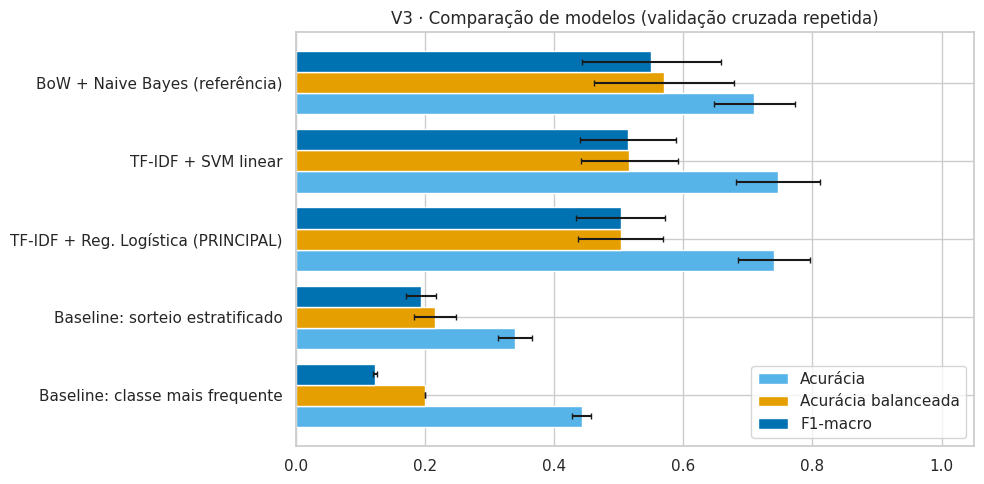

In [16]:
# VISUALIZAÇÃO 3 — comparação de modelos (média ± desvio entre folds)
def plot_modelos(res, nome_fig, titulo):
    nomes = sorted(res, key=lambda n: res[n]["f1_macro"][0])
    fig, ax = plt.subplots(figsize=(10, 0.7 * len(nomes) + 1.5))
    h = 0.27
    for k, (m, rot, c) in enumerate([("acuracia", "Acurácia", PALETA[5]), ("acuracia_balanceada", "Acurácia balanceada", PALETA[4]),
                                      ("f1_macro", "F1-macro", PALETA[0])]):
        ax.barh([i + (k - 1) * h for i in range(len(nomes))], [res[n][m][0] for n in nomes], height=h,
                xerr=[res[n][m][1] for n in nomes], color=c, label=rot, capsize=2)
    ax.set_yticks(range(len(nomes))); ax.set_yticklabels(nomes); ax.set_xlim(0, 1.05)
    ax.set_title(titulo); ax.legend(loc="lower right")
    salvar(nome_fig); plt.show()

plot_modelos(resultados, "v3_comparacao_modelos", "V3 · Comparação de modelos (validação cruzada repetida)")

### 4.2 Matriz de confusão e desempenho por classe (modelo principal)
Cada artigo é previsto por um modelo que **não o viu no treino** (`cross_val_predict`).

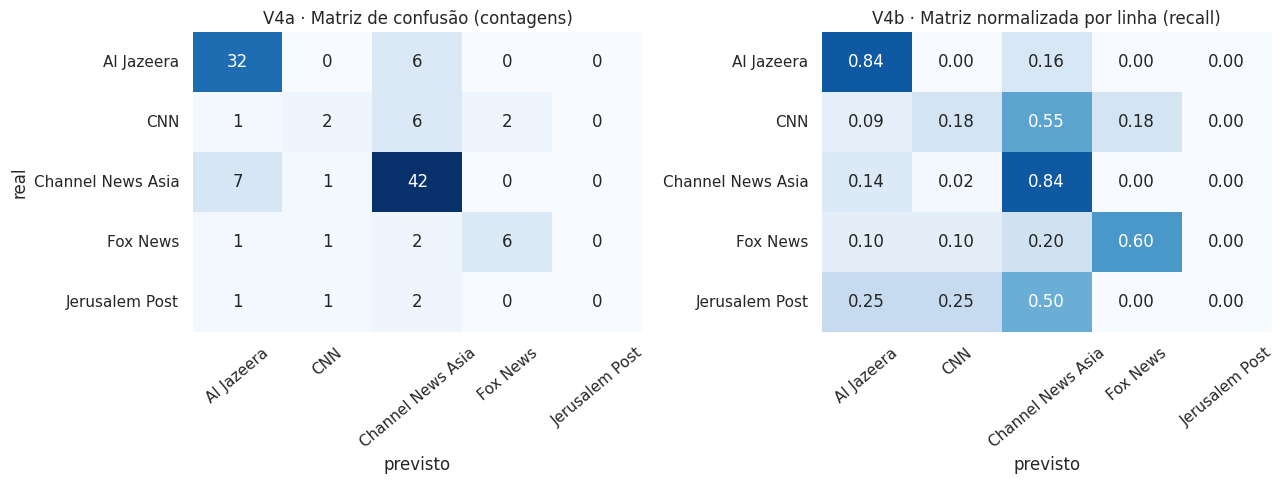

,precision,recall,f1-score,support
Al Jazeera,0.762,0.842,0.800,38.000
CNN,0.400,0.182,0.250,11.000
Channel News Asia,0.724,0.840,0.778,50.000
Fox News,0.750,0.600,0.667,10.000
Jerusalem Post,0.000,0.000,0.000,4.000
accuracy,0.726,0.726,0.726,0.726
macro avg,0.527,0.493,0.499,113.000
weighted avg,0.682,0.726,0.697,113.000


In [17]:
cv_unico = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
proba = cross_val_predict(MODELOS[PRINCIPAL], X_masc, y, cv=cv_unico, method="predict_proba")
classes = np.array(sorted(set(y)))
pred = classes[proba.argmax(axis=1)]
confianca = proba.max(axis=1)

cm = confusion_matrix(y, pred, labels=classes)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=ax[0], cbar=False)
ax[0].set_title("V4a · Matriz de confusão (contagens)"); ax[0].set_xlabel("previsto"); ax[0].set_ylabel("real")
cmn = cm / cm.sum(axis=1, keepdims=True)
sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, xticklabels=classes, yticklabels=classes, ax=ax[1], cbar=False)
ax[1].set_title("V4b · Matriz normalizada por linha (recall)"); ax[1].set_xlabel("previsto"); ax[1].set_ylabel("")
for a in ax: a.tick_params(axis="x", rotation=40)
salvar("v4_matriz_confusao"); plt.show()

rel = pd.DataFrame(classification_report(y, pred, output_dict=True, zero_division=0)).T.round(3)
rel

### 4.3 Análise dos erros

In [18]:
df_pred = df[["id", "titulo", ALVO, "num_palavras"]].copy()
df_pred["previsto"] = pred; df_pred["confianca"] = confianca.round(3)
df_pred["erro"] = df_pred[ALVO] != df_pred["previsto"]
erros = df_pred[df_pred["erro"]].sort_values("confianca", ascending=False)

print(f"Erros: {len(erros)} de {len(df_pred)} ({100 * len(erros) / len(df_pred):.1f}%)\n")
print("Pares mais confundidos (real → previsto):")
print(erros.groupby([ALVO, "previsto"]).size().sort_values(ascending=False).head(8).to_string(), "\n")

df_pred["faixa_tamanho"] = pd.qcut(df_pred["num_palavras"], 4, duplicates="drop")
print("Taxa de erro por faixa de tamanho do texto (nº de palavras):")
print(df_pred.groupby("faixa_tamanho", observed=True)["erro"].agg(taxa_erro="mean", n="count").round(3).to_string(), "\n")

print("Erros MAIS CONFIANTES do modelo (os mais interessantes para discutir):")
erros[["titulo", ALVO, "previsto", "confianca", "num_palavras"]].head(8).assign(titulo=lambda d: d["titulo"].astype(str).str[:70])

Erros: 31 de 113 (27.4%)

Pares mais confundidos (real → previsto):
veiculo            previsto         
Channel News Asia  Al Jazeera           7
Al Jazeera         Channel News Asia    6
CNN                Channel News Asia    6
                   Fox News             2
Jerusalem Post     Channel News Asia    2
Fox News           Channel News Asia    2
CNN                Al Jazeera           1
Channel News Asia  CNN                  1 

Taxa de erro por faixa de tamanho do texto (nº de palavras):
                 taxa_erro   n
faixa_tamanho                 
(46.999, 441.0]      0.310  29
(441.0, 608.0]       0.200  30
(608.0, 897.0]       0.077  26
(897.0, 3135.0]      0.500  28 

Erros MAIS CONFIANTES do modelo (os mais interessantes para discutir):


,titulo,veiculo,previsto,confianca,num_palavras
57,This small island off Yemen is now a strategic...,CNN,Channel News Asia,0.730,2151
14,Qatar says efforts under way to end Iran-US wa...,Al Jazeera,Channel News Asia,0.710,441
77,Israeli minister calls to strip Gaza film dire...,Channel News Asia,Al Jazeera,0.639,433
54,"Ed Sheeran tour: Macklemore dropped, other ope...",CNN,Fox News,0.497,1139
51,"An ambassador in Ljubljana, but not in London:...",CNN,Channel News Asia,0.495,1040
99,"Trump offers US$5,000 to every American if Rep...",Channel News Asia,CNN,0.483,969
0,Israel captures top Hamas commander in Gaza st...,Fox News,Channel News Asia,0.457,453
43,Ireland beats Israel 3-0 wearing black armband...,Al Jazeera,Channel News Asia,0.456,60


**Como ler os erros (preencher no relatório com os números acima):**
- Textos **curtos** tendem a errar mais: há poucos termos para o modelo se apoiar.
- Veículos com **cobertura parecida** (por exemplo, agências e portais em inglês que usam texto de agência) devem ser os mais confundidos entre si.
- Erros com **alta confiança** costumam ser matérias de agência republicadas ou matérias *fora do tema* — são limitações do corpus, não do enquadramento.

### 4.4 O que o modelo aprendeu? (termos mais característicos de cada classe)
Os coeficientes da regressão logística (treinada com todos os dados) ligam o classificador à análise de *framing* do T1.

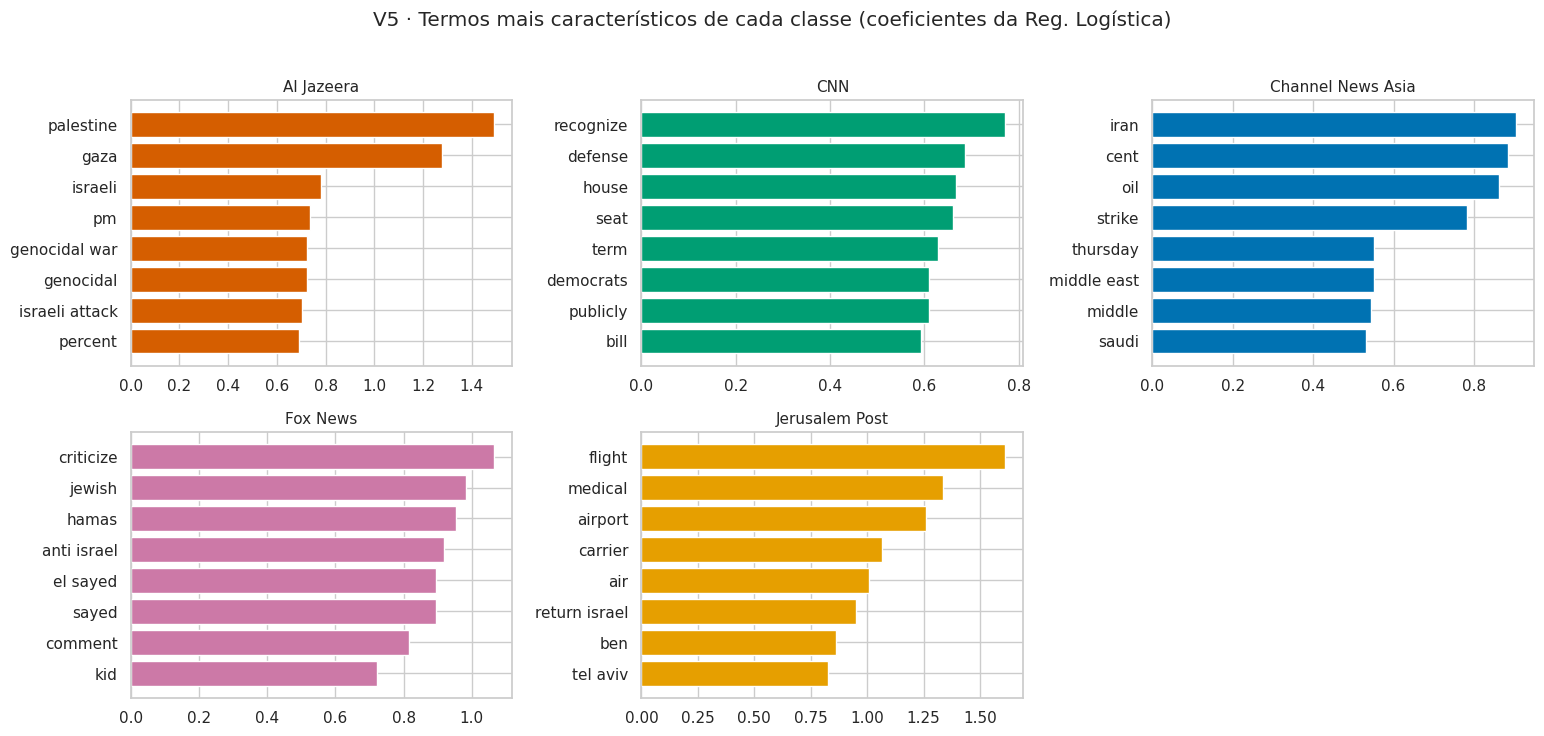

,Al Jazeera,CNN,Channel News Asia,Fox News,Jerusalem Post
0,palestine,recognize,iran,criticize,flight
1,gaza,defense,cent,jewish,medical
2,israeli,house,oil,hamas,airport
3,pm,seat,strike,anti israel,carrier
4,genocidal war,term,thursday,el sayed,air
5,genocidal,democrats,middle east,sayed,return israel
6,israeli attack,publicly,middle,comment,ben
7,percent,bill,saudi,kid,tel aviv


In [19]:
modelo_final = MODELOS[PRINCIPAL].fit(X_masc, y)
vet = modelo_final.named_steps["tfidfvectorizer"]; lr = modelo_final.named_steps["logisticregression"]
termos = np.array(vet.get_feature_names_out())
coefs = lr.coef_ if len(lr.classes_) > 2 else np.vstack([-lr.coef_[0], lr.coef_[0]])

TOPK = 8
tops = {c: [(termos[j], coefs[i][j]) for j in np.argsort(coefs[i])[::-1][:TOPK]] for i, c in enumerate(lr.classes_)}

# VISUALIZAÇÃO 5 — termos mais característicos por classe
nc = len(lr.classes_); ncols = 3; nrows = int(np.ceil(nc / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 3.6 * nrows)); axes = np.array(axes).reshape(-1)
for ax, (c, lista) in zip(axes, tops.items()):
    ts, ws = zip(*lista)
    ax.barh(ts[::-1], ws[::-1], color=cor.get(c, PALETA[0])); ax.set_title(c, fontsize=11)
for ax in axes[nc:]: ax.axis("off")
fig.suptitle("V5 · Termos mais característicos de cada classe (coeficientes da Reg. Logística)", y=1.02)
salvar("v5_termos_por_classe"); plt.show()
pd.DataFrame({c: [t for t, _ in l] for c, l in tops.items()})

### 4.5 Controle de vazamento: o modelo "acerta" só porque vê o nome do veículo?
Comparamos o mesmo modelo treinado com o texto **com** os nomes de veículos/agências (`lemas_bruto`) e **sem** (`lemas_masc`).
Se a diferença for grande, parte do desempenho vem de **atalhos** e não de vocabulário editorial.

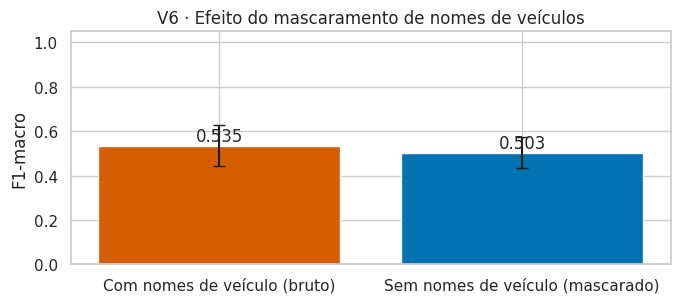

Queda de F1-macro ao mascarar: +0.032


In [20]:
res_vaz = {"Com nomes de veículo (bruto)": avaliar(MODELOS[PRINCIPAL], df["lemas_bruto"], y, cv),
           "Sem nomes de veículo (mascarado)": resultados[PRINCIPAL]}

fig, ax = plt.subplots(figsize=(7, 3.2))
nomes = list(res_vaz); vals = [res_vaz[n]["f1_macro"][0] for n in nomes]; errs = [res_vaz[n]["f1_macro"][1] for n in nomes]
ax.bar(nomes, vals, yerr=errs, color=[PALETA[1], PALETA[0]], capsize=4)
for i, v in enumerate(vals): ax.text(i, v + 0.02, f"{v:.3f}", ha="center")
ax.set_ylim(0, 1.05); ax.set_ylabel("F1-macro"); ax.set_title("V6 · Efeito do mascaramento de nomes de veículos")
salvar("v6_vazamento_nomes"); plt.show()
print(f"Queda de F1-macro ao mascarar: {vals[0] - vals[1]:+.3f}")

### 4.6 Alvo alternativo: grupo de veículos (EUA × Oriente Médio × Ásia Oriental)

In [21]:
res_grupo = None
if ALVO != "grupo" and "grupo" in df.columns and df["grupo"].nunique() >= 2:
    yg = df["grupo"].values
    ns_g = int(min(5, pd.Series(yg).value_counts().min()))
    if ns_g >= 2:
        cv_g = RepeatedStratifiedKFold(n_splits=ns_g, n_repeats=5, random_state=SEED)
        res_grupo = {n: avaliar(MODELOS[n], X_masc, yg, cv_g)
                     for n in ["Baseline: classe mais frequente", "BoW + Naive Bayes (referência)", PRINCIPAL]}
        print(f"Alvo = grupo ({df['grupo'].nunique()} classes; {ns_g} folds)")
        display(tabela(res_grupo))
else:
    print("Alvo alternativo não aplicável.")

Alvo = grupo (3 classes; 5 folds)


,modelo,acuracia,acuracia_balanceada,f1_macro
0,TF-IDF + Reg. Logística (PRINCIPAL),0.810 ± 0.103,0.783 ± 0.114,0.788 ± 0.116
1,BoW + Naive Bayes (referência),0.767 ± 0.094,0.758 ± 0.104,0.753 ± 0.103
2,Baseline: classe mais frequente,0.443 ± 0.010,0.333 ± 0.000,0.205 ± 0.003


### 4.7 Balanceamento, hold-out e ajuste de hiperparâmetros (como no roteiro da disciplina)
Seguimos o roteiro do notebook de aprendizado supervisionado das aulas: (1) efeito de `class_weight`, (2) **separação treino/teste estratificada
*antes* de qualquer ajuste**, (3) `GridSearchCV` **somente no treino**, (4) avaliação final no teste reservado, (5) métricas por classe calculadas
"à mão" a partir de VP/FP/FN/VN e conferidas com o scikit-learn, (6) ROC-AUC e Average Precision.

> **Aviso:** com classes de 4 a 50 artigos, o conjunto de teste terá poucos exemplos das classes pequenas (ex.: 1 artigo do menor veículo).
> Por isso a **validação cruzada repetida (seções anteriores) continua sendo o número principal**; o hold-out é a conferência final no formato da disciplina.

In [22]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import (precision_recall_fscore_support, roc_auc_score, average_precision_score,
                             accuracy_score, balanced_accuracy_score, f1_score)
from sklearn.preprocessing import label_binarize

# (1) class_weight: sem x com balanceamento (não cria exemplos, só pesa mais os erros da classe pequena)
linhas = []
for peso in [None, "balanced"]:
    pipe = make_pipeline(tf(), LogisticRegression(C=10, class_weight=peso, max_iter=3000))
    r = avaliar(pipe, X_masc, y, cv)
    linhas.append({"class_weight": str(peso), **{m: f"{v[0]:.3f} ± {v[1]:.3f}" for m, v in r.items()}})
tab_peso = pd.DataFrame(linhas); display(tab_peso)

,class_weight,acuracia,acuracia_balanceada,f1_macro
0,None,0.726 ± 0.065,0.445 ± 0.081,0.442 ± 0.101
1,balanced,0.740 ± 0.056,0.503 ± 0.066,0.503 ± 0.069


In [23]:
# (2) hold-out estratificado: PRIMEIRO separamos; o TfidfVectorizer só é ajustado no treino (dentro do Pipeline)
Xtr, Xte, ytr, yte = train_test_split(X_masc, y, test_size=0.25, stratify=y, random_state=SEED)
print("Treino:", len(Xtr), "| Teste:", len(Xte)); print(pd.DataFrame({"treino": pd.Series(ytr).value_counts(), "teste": pd.Series(yte).value_counts()}))

# (3) GridSearchCV só no treino (escolha de C por F1-macro)
ns_tr = int(min(5, pd.Series(ytr).value_counts().min()))
busca = GridSearchCV(make_pipeline(tf(), LogisticRegression(class_weight="balanced", max_iter=3000)),
                     {"logisticregression__C": [0.1, 1, 10, 100]},
                     cv=StratifiedKFold(ns_tr, shuffle=True, random_state=SEED), scoring="f1_macro")
busca.fit(Xtr, ytr)
print(f"Melhor C: {busca.best_params_['logisticregression__C']} | F1-macro na validação cruzada do treino: {busca.best_score_:.3f} ({ns_tr} folds)")

# (4) avaliação final no teste reservado
pred_te = busca.predict(Xte); cl = busca.classes_
res_holdout = {"acuracia": accuracy_score(yte, pred_te), "acuracia_balanceada": balanced_accuracy_score(yte, pred_te),
               "f1_macro": f1_score(yte, pred_te, average="macro", zero_division=0)}
print({k: round(v, 3) for k, v in res_holdout.items()})

Treino: 84 | Teste: 29
                   treino  teste
Al Jazeera             28     10
CNN                     8      3
Channel News Asia      37     13
Fox News                8      2
Jerusalem Post          3      1
Melhor C: 0.1 | F1-macro na validação cruzada do treino: 0.433 (3 folds)
{'acuracia': 0.724, 'acuracia_balanceada': np.float64(0.547), 'f1_macro': 0.545}


In [24]:
# (5) métricas por classe "à mão" a partir da matriz de confusão (classe positiva = a própria classe, um-contra-todos)
cmt = confusion_matrix(yte, pred_te, labels=cl); linhas = []
for i, c in enumerate(cl):
    vp = cmt[i, i]; fp = cmt[:, i].sum() - vp; fn = cmt[i, :].sum() - vp; vn = cmt.sum() - vp - fp - fn
    linhas.append({"classe": c, "VP": vp, "FP": fp, "FN": fn, "VN": vn,
                   "precisão": vp / (vp + fp) if vp + fp else 0, "recall": vp / (vp + fn) if vp + fn else 0,
                   "F1": 2 * vp / (2 * vp + fp + fn) if (2 * vp + fp + fn) else 0, "especificidade": vn / (vn + fp) if vn + fp else 0})
tab_classe = pd.DataFrame(linhas)
p_sk, r_sk, f_sk, _ = precision_recall_fscore_support(yte, pred_te, labels=cl, zero_division=0)
assert np.allclose(tab_classe["precisão"], p_sk) and np.allclose(tab_classe["recall"], r_sk) and np.allclose(tab_classe["F1"], f_sk)
print("Conferência manual x scikit-learn: OK"); display(tab_classe.round(3))

# (6) métricas que usam probabilidades (todos os limiares): ROC-AUC e Average Precision, média macro um-contra-todos
Yb = label_binarize(yte, classes=cl); P = busca.predict_proba(Xte)
res_holdout["roc_auc_macro"] = roc_auc_score(Yb, P, average="macro"); res_holdout["ap_macro"] = average_precision_score(Yb, P, average="macro")
print(f"ROC-AUC macro: {res_holdout['roc_auc_macro']:.3f} | Average Precision macro: {res_holdout['ap_macro']:.3f}")

Conferência manual x scikit-learn: OK


,classe,VP,FP,FN,VN,precisão,recall,F1,especificidade
0,Al Jazeera,8,4,2,15,0.667,0.800,0.727,0.789
1,CNN,2,0,1,26,1.000,0.667,0.800,1.000
2,Channel News Asia,10,2,3,14,0.833,0.769,0.800,0.875
3,Fox News,1,2,1,25,0.333,0.500,0.400,0.926
4,Jerusalem Post,0,0,1,28,0.000,0.000,0.000,1.000


ROC-AUC macro: 0.843 | Average Precision macro: 0.665


### 4.8 Semelhança entre classes (continuidade com o T1)
Similaridade de cosseno entre os **centróides TF-IDF** de cada veículo — equivalente à matriz do T1, agora com texto mascarado.

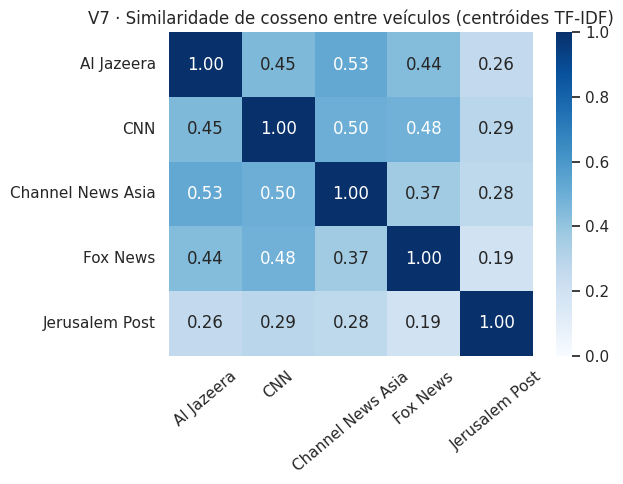

In [25]:
Xt = tfidf.fit_transform(df["lemas_masc"])
cent = np.vstack([np.asarray(Xt[(y == c)].mean(axis=0)).ravel() for c in classes])
sim = cosine_similarity(cent)
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(pd.DataFrame(sim, index=classes, columns=classes), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
ax.set_title("V7 · Similaridade de cosseno entre veículos (centróides TF-IDF)"); ax.tick_params(axis="x", rotation=40)
salvar("v7_similaridade_veiculos"); plt.show()

## Análises complementares de framing (ainda com técnicas tradicionais)
Quatro análises que usam o conteúdo da disciplina (agrupamento, busca por similaridade, sentimento e extração de relações) e respondem
a perguntas diferentes da classificação:
1. **Agrupamento (não supervisionado):** sem olhar os rótulos, os textos se agrupam por veículo? (K-Means + LSA, silhouette, ARI, estabilidade)
2. **Busca textual:** TF-IDF encontra um artigo a partir do título? (hit@k, MRR) — base para o RAG da Etapa 6
3. **Tom por lado do conflito:** o tom (VADER) das frases sobre Israel × Palestina/Gaza/Hamas difere entre veículos?
4. **Agência:** em eventos de violência, quem é **agente** e quem é **paciente** (voz ativa × passiva), por veículo?

### A. Agrupamento — os veículos aparecem como clusters?
LSA (SVD truncado do TF-IDF) reduz a dimensionalidade; K-Means agrupa **sem usar rótulos**. Só depois comparamos com o veículo real
(**ARI** e **NMI**, métricas extrínsecas) e medimos a **estabilidade** do agrupamento entre sementes (ARI entre execuções), como no roteiro das aulas.

In [26]:
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans
from sklearn.preprocessing import Normalizer
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score

Xt_all = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9, sublinear_tf=True).fit_transform(df["lemas_masc"])
n_svd = int(min(50, Xt_all.shape[1] - 1, len(df) - 1))
svd = TruncatedSVD(n_components=n_svd, random_state=SEED); Z = Normalizer(copy=False).fit_transform(svd.fit_transform(Xt_all))
print(f"LSA: {n_svd} componentes, variância explicada {svd.explained_variance_ratio_.sum():.1%}")

K_MAX = int(min(8, len(df) - 1)); linhas = []
for k in range(2, K_MAX + 1):
    km_k = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    linhas.append({"K": k, "inercia": km_k.inertia_, "silhouette": silhouette_score(Z, km_k.labels_), "davies_bouldin": davies_bouldin_score(Z, km_k.labels_)})
met_k = pd.DataFrame(linhas); display(met_k.round(3))

K_REF = len(classes)  # comparamos com o nº real de veículos
km = KMeans(n_clusters=K_REF, n_init=10, random_state=SEED).fit(Z); rot = km.labels_
ari = adjusted_rand_score(y, rot); nmi = normalized_mutual_info_score(y, rot)
aris_seed = [adjusted_rand_score(rot, KMeans(n_clusters=K_REF, n_init=10, random_state=s).fit_predict(Z)) for s in (1, 7, 13, 21, 99)]
sil_real = silhouette_score(Z, pd.Series(y).astype("category").cat.codes)
res_cluster = {"K": K_REF, "ARI_vs_veiculo": round(ari, 3), "NMI_vs_veiculo": round(nmi, 3),
               "estabilidade_ARI_sementes": round(float(np.mean(aris_seed)), 3), "silhouette_clusters": round(float(silhouette_score(Z, rot)), 3),
               "silhouette_rotulos_reais": round(float(sil_real), 3)}
print(res_cluster)

LSA: 50 componentes, variância explicada 64.1%


,K,inercia,silhouette,davies_bouldin
0,2,95.738,0.038,3.950
1,3,91.329,0.057,3.675
2,4,88.172,0.069,3.559
3,5,85.156,0.076,3.662
4,6,82.290,0.081,3.377
5,7,80.140,0.093,3.167
6,8,77.817,0.095,2.966


{'K': 5, 'ARI_vs_veiculo': 0.12, 'NMI_vs_veiculo': np.float64(0.21), 'estabilidade_ARI_sementes': 0.385, 'silhouette_clusters': 0.076, 'silhouette_rotulos_reais': 0.008}


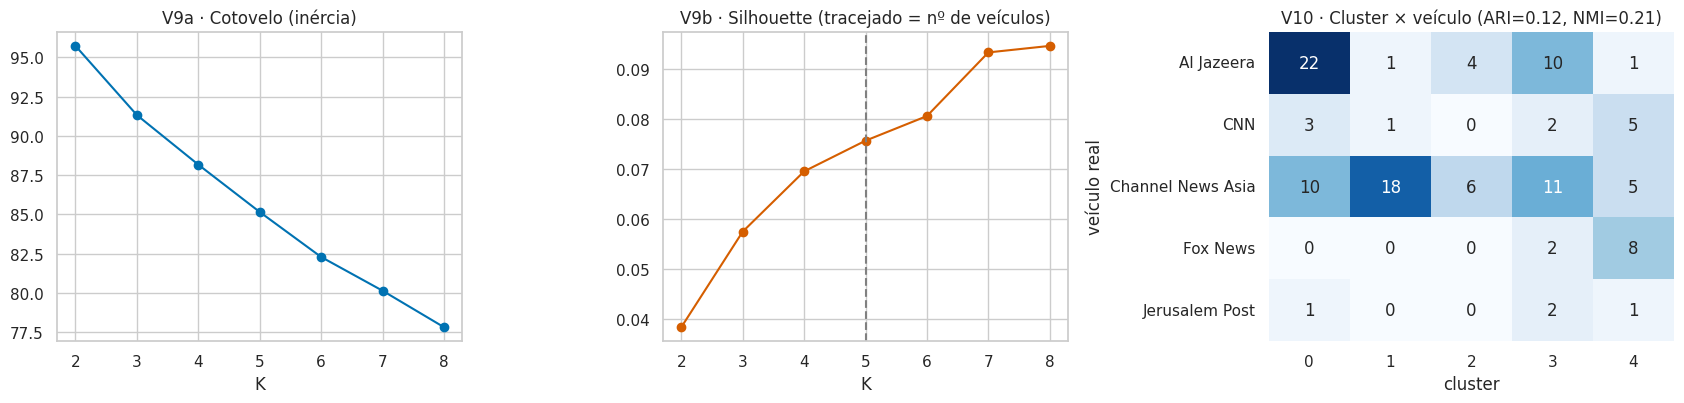

In [27]:
# VISUALIZAÇÃO 9 — escolha de K (cotovelo e silhouette) | VISUALIZAÇÃO 10 — clusters x veículo reais
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].plot(met_k["K"], met_k["inercia"], "o-", color=PALETA[0]); ax[0].set_title("V9a · Cotovelo (inércia)"); ax[0].set_xlabel("K")
ax[1].plot(met_k["K"], met_k["silhouette"], "o-", color=PALETA[1]); ax[1].axvline(K_REF, ls="--", color="gray"); ax[1].set_title("V9b · Silhouette (tracejado = nº de veículos)"); ax[1].set_xlabel("K")
ct = pd.crosstab(pd.Series(y, name="veículo real"), pd.Series(rot, name="cluster"))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", ax=ax[2], cbar=False); ax[2].set_title(f"V10 · Cluster × veículo (ARI={ari:.2f}, NMI={nmi:.2f})")
salvar("v9_v10_agrupamento"); plt.show()

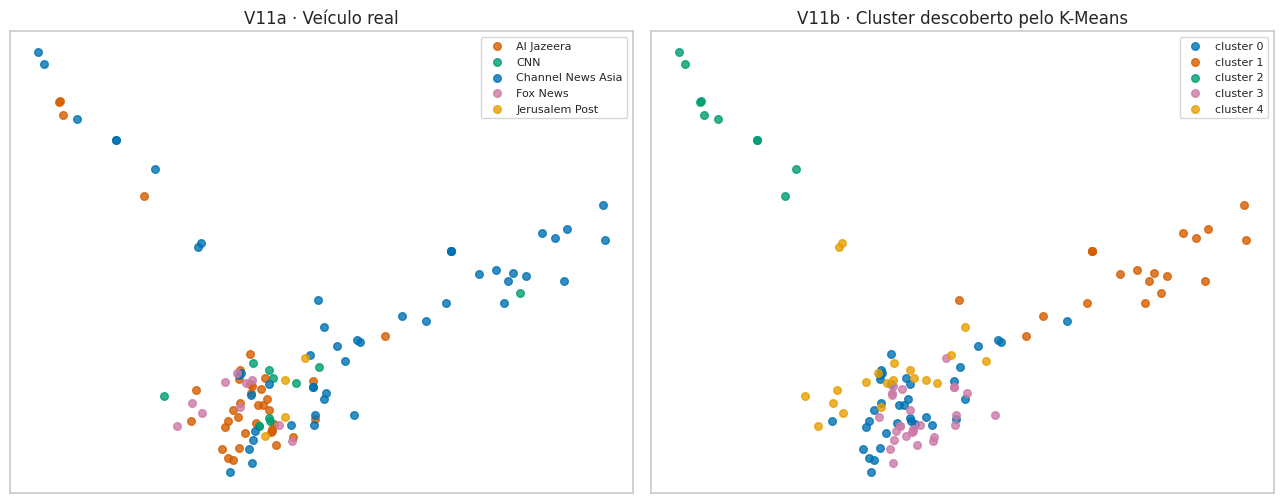

In [28]:
# VISUALIZAÇÃO 11 — mesmo espaço (PCA 2D do LSA): cores = veículo real x cores = cluster descoberto
P2 = PCA(n_components=2, random_state=SEED).fit_transform(Z)
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
for c in classes:
    m = y == c; ax[0].scatter(P2[m, 0], P2[m, 1], s=30, alpha=0.8, color=cor[c], label=c)
ax[0].legend(fontsize=8); ax[0].set_title("V11a · Veículo real")
for k in range(K_REF):
    m = rot == k; ax[1].scatter(P2[m, 0], P2[m, 1], s=30, alpha=0.8, color=PALETA[k % len(PALETA)], label=f"cluster {k}")
ax[1].legend(fontsize=8); ax[1].set_title("V11b · Cluster descoberto pelo K-Means")
for a in ax: a.set_xticks([]); a.set_yticks([])
salvar("v11_clusters_vs_veiculos"); plt.show()

**Leitura:** ARI/NMI próximos de 0 indicam que os agrupamentos **não** coincidem com os veículos (a estrutura dominante do texto é outra, p. ex. tema ou tamanho);
valores altos indicam que o vocabulário separa os veículos mesmo sem rótulos. Compare também o silhouette dos clusters com o dos rótulos reais: se o dos rótulos
for pior, os veículos se sobrepõem no espaço lexical. Estabilidade baixa (ARI entre sementes) significa que o agrupamento não é confiável.

### B. Busca textual com TF-IDF (título → artigo)
Usamos o **título** como consulta e verificamos em que posição o **artigo correto** aparece (similaridade de cosseno). Métricas: **hit@1, hit@5** e **MRR**.
É uma avaliação objetiva da recuperação, sem gabarito manual. *Ressalva:* se o título aparecer no corpo do texto a busca fica fácil demais; removemos ocorrências exatas do título e os nomes de veículos.

In [29]:
from sklearn.metrics.pairwise import cosine_similarity

def sem_titulo(texto, titulo):
    t = mascarar(str(titulo)); return texto.replace(t, " ") if len(t) > 10 else texto
docs_busca = [sem_titulo(a, b) for a, b in zip(df["texto_masc"], df["titulo"])]
consultas = [mascarar(normalizar(str(t))) for t in df["titulo"]]

def avaliar_busca(S):
    # S[i, j] = similaridade entre a consulta i e o documento j; o documento correto é j = i
    pos = np.array([(S[i] > S[i, i]).sum() + 1 for i in range(len(S))])
    return {"hit@1": float((pos <= 1).mean()), "hit@5": float((pos <= 5).mean()), "MRR": float((1 / pos).mean())}

res_busca = {}
for nome, ng in [("TF-IDF unigramas", (1, 1)), ("TF-IDF uni+bigramas", (1, 2))]:
    v = TfidfVectorizer(ngram_range=ng, strip_accents="unicode", sublinear_tf=True).fit(docs_busca)
    res_busca[nome] = avaliar_busca(cosine_similarity(v.transform(consultas), v.transform(docs_busca)))
tab_busca = pd.DataFrame(res_busca).T.round(3); display(tab_busca)

,hit@1,hit@5,MRR
TF-IDF unigramas,0.770,0.982,0.86
TF-IDF uni+bigramas,0.752,0.982,0.85


### C. Tom por lado do conflito (VADER)
Para cada **frase** que menciona só Israel (IDF, Netanyahu) ou só Palestina/Gaza/Hamas (a mesma regra do T1, agora com fronteira de palavra),
calculamos o escore composto do VADER (−1 a +1). O corpus já está em inglês, que é a língua para a qual o VADER foi criado.

> **Cuidado de interpretação (aula de análise de sentimentos):** o VADER mede o **tom da frase inteira**, não a atitude do veículo *em relação* ao ator. Uma frase neutra sobre
> um ataque ("Hamas attacked a town") tem tom negativo por causa do **evento**. Trate a diferença entre lados como indício a ser lido junto com os exemplos, não como prova de viés.

In [30]:
try:
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
except ImportError:
    import subprocess, sys; subprocess.run([sys.executable, "-m", "pip", "install", "-q", "vaderSentiment"], check=True)
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from scipy.stats import mannwhitneyu

vader = SentimentIntensityAnalyzer()
RE_ISR = re.compile(r"\b(?:israel\w*|idf|netanyahu)\b", re.I)
RE_PAL = re.compile(r"\b(?:palestin\w*|gaza\w*|hamas|west bank)\b", re.I)
def lado_do_texto(txt):
    i, p = bool(RE_ISR.search(txt)), bool(RE_PAL.search(txt))
    return "Israel" if i and not p else "Palestina/Gaza/Hamas" if p and not i else None

nlp_sent = spacy.blank("en"); nlp_sent.add_pipe("sentencizer")
linhas = []
for i, doc in enumerate(nlp_sent.pipe(df["texto_masc"].tolist(), batch_size=16)):
    for sent in doc.sents:
        lado = lado_do_texto(sent.text)
        if lado: linhas.append({"veiculo": y[i], "lado": lado, "composto": vader.polarity_scores(sent.text)["compound"], "frase": sent.text})
df_tom = pd.DataFrame(linhas)
agg = df_tom.groupby(["veiculo", "lado"])["composto"].agg(media="mean", dp="std", n="count").reset_index()
agg["ep"] = agg["dp"] / np.sqrt(agg["n"])
pv = []
for v in classes:
    a = df_tom[(df_tom.veiculo == v) & (df_tom.lado == "Israel")]["composto"]; b = df_tom[(df_tom.veiculo == v) & (df_tom.lado == "Palestina/Gaza/Hamas")]["composto"]
    pv.append({"veiculo": v, "n_Israel": len(a), "n_Palestina": len(b), "p_valor_MannWhitney": mannwhitneyu(a, b).pvalue if min(len(a), len(b)) >= 5 else np.nan})
tab_tom = agg.pivot(index="veiculo", columns="lado", values="media").join(pd.DataFrame(pv).set_index("veiculo")).round(3); display(tab_tom)
print("(p-valor só onde há ≥5 frases por lado; são vários testes, então não corrigidos: use com cautela)")

,Israel,Palestina/Gaza/Hamas,n_Israel,n_Palestina,p_valor_MannWhitney
veiculo,,,,,
Al Jazeera,-0.149,-0.061,196,129,0.084
CNN,-0.081,-0.206,60,23,0.237
Channel News Asia,-0.203,-0.101,206,35,0.241
Fox News,-0.081,-0.041,37,48,0.783
Jerusalem Post,0.114,-0.622,34,5,0.008


(p-valor só onde há ≥5 frases por lado; são vários testes, então não corrigidos: use com cautela)


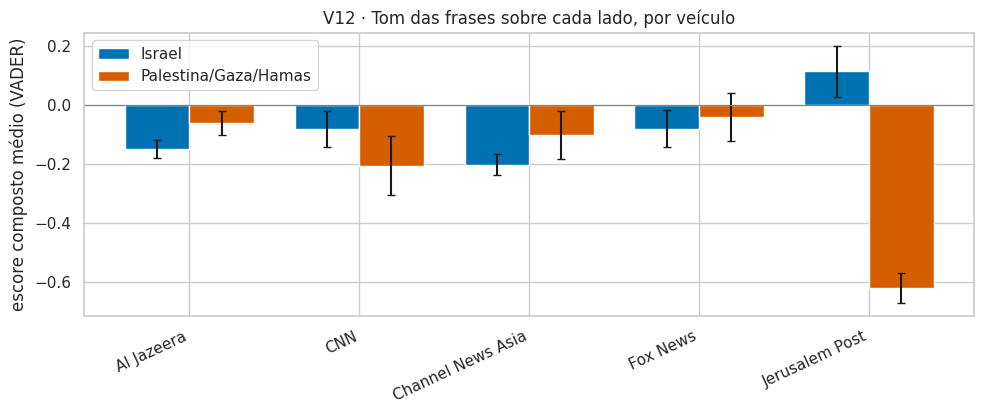

Frases mais negativas sobre cada lado (para ler os exemplos):

 Israel


,veiculo,composto,frase
542,Jerusalem Post,-0.9666,IDF troops kill 29-year-old terrorist The terr...
765,Channel News Asia,-0.9506,WORSENING TENSIONS Regional tensions were also...
599,Channel News Asia,-0.9403,Israeli strikes on Lebanon kills at least thre...



 Palestina/Gaza/Hamas


,veiculo,composto,frase
64,Fox News,-0.9313,"Approximately 72,000 Palestinians have been re..."
273,Al Jazeera,-0.9274,An aerial attack on another vehicle in central...
2,Fox News,-0.9231,"Instead, we pursue Hamas terrorists, thwart th..."


In [31]:
# VISUALIZAÇÃO 12 — tom médio das frases por lado e veículo (barras de erro = erro-padrão)
fig, ax = plt.subplots(figsize=(10, 4.3)); larg = 0.38
for k, (lado, cc) in enumerate([("Israel", PALETA[0]), ("Palestina/Gaza/Hamas", PALETA[1])]):
    s = agg[agg.lado == lado].set_index("veiculo").reindex(classes)
    ax.bar(np.arange(len(classes)) + (k - 0.5) * larg, s["media"], larg, yerr=s["ep"], color=cc, capsize=3, label=lado)
ax.axhline(0, color="gray", lw=0.8); ax.set_xticks(range(len(classes))); ax.set_xticklabels(classes, rotation=25, ha="right")
ax.set_ylabel("escore composto médio (VADER)"); ax.set_title("V12 · Tom das frases sobre cada lado, por veículo"); ax.legend()
salvar("v12_tom_por_lado"); plt.show()
print("Frases mais negativas sobre cada lado (para ler os exemplos):")
for lado in ["Israel", "Palestina/Gaza/Hamas"]:
    print("\n", lado); display(df_tom[df_tom.lado == lado].nsmallest(3, "composto")[["veiculo", "composto", "frase"]].assign(frase=lambda d: d["frase"].str[:160]))

### D. Agência em eventos de violência (dependências sintáticas)
Seguindo a aula de KG-RAG (extração de relações por **POS + dependências**), identificamos verbos de violência (kill, attack, strike, bomb, launch, fire...) e, pela árvore de dependências,
quem é o **agente** (sujeito da voz ativa ou *by-phrase* da passiva) e o **paciente** (objeto ou sujeito da passiva). A pergunta de framing é: **cada lado aparece mais como agente ou como vítima?**
Construímos antes um **gabarito manual** de frases controladas e medimos o extrator (acertos e erros), como na avaliação de KG da aula — sem revisar manualmente o que sai no corpus.

In [32]:
nlp_dep = spacy.load("en_core_web_sm", disable=["ner"])
VIOLENTOS = {"kill", "attack", "strike", "bomb", "shell", "murder", "massacre", "target", "launch", "fire", "shoot", "assault", "raid", "destroy"}

def eventos_violencia(doc):
    ev = []
    for tok in doc:
        if tok.pos_ != "VERB" or tok.lemma_.lower() not in VIOLENTOS: continue
        filhos = list(tok.children)
        if tok.dep_ == "conj" and tok.head.pos_ == "VERB":   # "Hamas attacked and killed ..." herda o sujeito
            filhos += [c for c in tok.head.children if c.dep_ in ("nsubj", "nsubjpass")]
        agente = paciente = None; passiva = False; com_by = False
        for c in filhos:
            sub = " ".join(t.text for t in c.subtree)
            if c.dep_ == "nsubj": agente = agente or lado_do_texto(sub)
            elif c.dep_ == "nsubjpass": paciente = paciente or lado_do_texto(sub); passiva = True
            elif c.dep_ == "dobj": paciente = paciente or lado_do_texto(sub)
            elif c.dep_ == "agent":
                com_by = True
                for g in c.children:
                    if g.dep_ == "pobj": agente = agente or lado_do_texto(" ".join(t.text for t in g.subtree))
        ev.append({"verbo": tok.lemma_.lower(), "agente": agente, "paciente": paciente, "passiva": passiva, "com_by": com_by})
    return ev

# gabarito manual: frases controladas e o evento esperado (verbo, agente, paciente)
GABARITO = [
    ("Israel launched airstrikes on Gaza.", ("launch", "Israel", None)),
    ("Hamas attacked Israeli soldiers.", ("attack", "Palestina/Gaza/Hamas", "Israel")),
    ("Palestinians were killed by Israeli strikes.", ("kill", "Israel", "Palestina/Gaza/Hamas")),
    ("Dozens were killed in the city.", ("kill", None, None)),
    ("The IDF killed three militants.", ("kill", "Israel", None)),
    ("Israelis were attacked by Hamas fighters.", ("attack", "Palestina/Gaza/Hamas", "Israel")),
    ("Israeli forces struck a school.", ("strike", "Israel", None)),
    ("Hamas fired rockets and killed two civilians.", ("fire", "Palestina/Gaza/Hamas", None)),
]
linhas = []
for frase, (v, a, p) in GABARITO:
    ev = [e for e in eventos_violencia(nlp_dep(frase)) if e["verbo"] == v]; e = ev[0] if ev else {"agente": "NÃO ACHOU", "paciente": "NÃO ACHOU"}
    linhas.append({"frase": frase, "esperado": (v, a, p), "extraído": (v, e["agente"], e["paciente"]), "agente_ok": e["agente"] == a, "paciente_ok": e["paciente"] == p})
aval_svo = pd.DataFrame(linhas); display(aval_svo)
acc_ag, acc_pa = aval_svo["agente_ok"].mean(), aval_svo["paciente_ok"].mean()
print(f"Acerto do AGENTE: {acc_ag:.0%} | acerto do PACIENTE: {acc_pa:.0%} (n={len(aval_svo)} frases controladas; amostra pequena e favorável: no corpus real o desempenho tende a ser menor)")

,frase,esperado,extraído,agente_ok,paciente_ok
0,Israel launched airstrikes on Gaza.,"(launch, Israel, None)","(launch, Israel, None)",True,True
1,Hamas attacked Israeli soldiers.,"(attack, Palestina/Gaza/Hamas, Israel)","(attack, Palestina/Gaza/Hamas, Israel)",True,True
2,Palestinians were killed by Israeli strikes.,"(kill, Israel, Palestina/Gaza/Hamas)","(kill, Israel, Palestina/Gaza/Hamas)",True,True
3,Dozens were killed in the city.,"(kill, None, None)","(kill, None, None)",True,True
4,The IDF killed three militants.,"(kill, Israel, None)","(kill, Israel, None)",True,True
5,Israelis were attacked by Hamas fighters.,"(attack, Palestina/Gaza/Hamas, Israel)","(attack, Palestina/Gaza/Hamas, Israel)",True,True
6,Israeli forces struck a school.,"(strike, Israel, None)","(strike, Israel, None)",True,True
7,Hamas fired rockets and killed two civilians.,"(fire, Palestina/Gaza/Hamas, None)","(fire, Palestina/Gaza/Hamas, None)",True,True


Acerto do AGENTE: 100% | acerto do PACIENTE: 100% (n=8 frases controladas; amostra pequena e favorável: no corpus real o desempenho tende a ser menor)


In [33]:
LIMITE_SVO = 400   # no corpus do T1 (113 artigos) processa tudo; limite só protege a corpus de contingência
idx_svo = np.arange(len(df)) if len(df) <= LIMITE_SVO else np.random.default_rng(SEED).choice(len(df), LIMITE_SVO, replace=False)
linhas = []
for i, doc in zip(idx_svo, nlp_dep.pipe(df["texto_masc"].iloc[idx_svo].tolist(), batch_size=8)):
    for e in eventos_violencia(doc): linhas.append({"veiculo": y[i], **e})
df_ev = pd.DataFrame(linhas)
print("Eventos de violência encontrados:", len(df_ev)); display(df_ev["verbo"].value_counts().head(8).to_frame("n"))

papeis = []
for v in classes:
    s = df_ev[df_ev.veiculo == v]
    for lado in ["Israel", "Palestina/Gaza/Hamas"]:
        ag, pa = int((s.agente == lado).sum()), int((s.paciente == lado).sum())
        papeis.append({"veiculo": v, "lado": lado, "como_agente": ag, "como_paciente": pa, "%agente": ag / (ag + pa) if ag + pa else np.nan,
                       "n_eventos": ag + pa})
tab_papeis = pd.DataFrame(papeis); display(tab_papeis.round(2))
pas = df_ev[df_ev.passiva]
sem_agente = pas.groupby("veiculo").agg(passivas=("com_by", "size"), sem_by_phrase=("com_by", lambda s: (~s).mean())).round(2)
sem_agente = sem_agente.rename(columns={"sem_by_phrase": "%passivas sem by-phrase (agente apagado)"})
display(sem_agente)

Eventos de violência encontrados: 348


,n
verbo,
kill,133
target,48
launch,38
attack,33
destroy,27
strike,24
shoot,14
fire,14


,veiculo,lado,como_agente,como_paciente,%agente,n_eventos
0,Al Jazeera,Israel,19,1,0.95,20
1,Al Jazeera,Palestina/Gaza/Hamas,5,17,0.23,22
2,CNN,Israel,4,1,0.80,5
3,CNN,Palestina/Gaza/Hamas,0,5,0.00,5
4,Channel News Asia,Israel,22,10,0.69,32
5,Channel News Asia,Palestina/Gaza/Hamas,4,3,0.57,7
6,Fox News,Israel,1,2,0.33,3
7,Fox News,Palestina/Gaza/Hamas,0,2,0.00,2
8,Jerusalem Post,Israel,2,2,0.50,4
9,Jerusalem Post,Palestina/Gaza/Hamas,1,0,1.00,1


,passivas,%passivas sem by-phrase (agente apagado)
veiculo,,
Al Jazeera,18,0.83
CNN,14,0.93
Channel News Asia,26,0.92
Fox News,9,1.00
Jerusalem Post,2,0.50


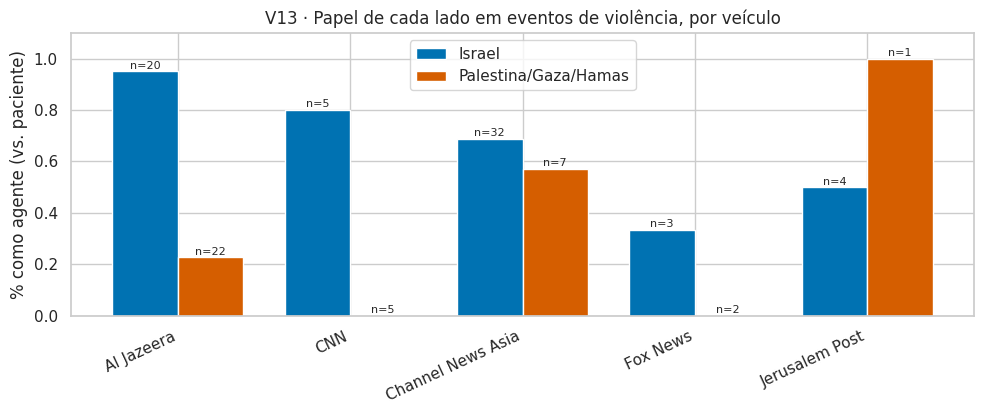

In [34]:
# VISUALIZAÇÃO 13 — % de vezes em que cada lado aparece como AGENTE (e não como paciente/vítima) nos eventos de violência
piv = tab_papeis.pivot(index="veiculo", columns="lado", values="%agente").reindex(classes)
nn = tab_papeis.pivot(index="veiculo", columns="lado", values="n_eventos").reindex(classes)
fig, ax = plt.subplots(figsize=(10, 4.3)); larg = 0.38
for k, (lado, cc) in enumerate([("Israel", PALETA[0]), ("Palestina/Gaza/Hamas", PALETA[1])]):
    b = ax.bar(np.arange(len(classes)) + (k - 0.5) * larg, piv[lado].fillna(0), larg, color=cc, label=lado)
    for r, n_ in zip(b, nn[lado].fillna(0)): ax.text(r.get_x() + r.get_width() / 2, r.get_height() + 0.01, f"n={int(n_)}", ha="center", fontsize=8)
ax.set_xticks(range(len(classes))); ax.set_xticklabels(classes, rotation=25, ha="right"); ax.set_ylim(0, 1.1)
ax.set_ylabel("% como agente (vs. paciente)"); ax.set_title("V13 · Papel de cada lado em eventos de violência, por veículo"); ax.legend()
salvar("v13_agencia_por_lado"); plt.show()

**Leitura (preencher no relatório):** barras altas = o lado aparece sobretudo **fazendo** a violência; baixas = aparece sobretudo **sofrendo**. Observe o `n` de cada barra:
com poucos eventos a diferença não é confiável. A fração de **passivas sem *by-phrase*** mostra o apagamento de quem pratica a ação ("civilians were killed", sem "by ...").
**Limites:** o analisador `en_core_web_sm` erra em frases longas e com coordenação; o gabarito é pequeno; só consideramos 14 verbos.

## Etapa 6 — Componente contemporâneo (somente após o pipeline tradicional)

Dois recursos de Hugging Face, ambos usados **depois** e **comparados** com o que já fizemos:

1. **Embeddings contextuais** (`sentence-transformers/all-MiniLM-L6-v2`): cada artigo vira um vetor denso de 384 dimensões
   (média dos vetores de blocos de ~180 palavras). Pergunta: *um embedding pré-treinado, que "entende" contexto, separa os veículos melhor que TF-IDF?*
2. **RAG** (recuperação por embeddings + `google/flan-t5-base`): perguntas com e sem resposta no corpus, com × sem contexto, como nos slides da disciplina.
3. **Sumarização** (`sshleifer/distilbart-cnn-12-6`): resume um artigo típico de cada veículo. Pergunta: *o resumo automático
   preserva o vocabulário carregado (enquadramento) ou o "neutraliza"?*

> Se o ambiente não tiver acesso ao Hugging Face (sem internet/GPU), as células abaixo avisam e são ignoradas — o restante do notebook continua válido.

In [35]:
HF_OK = False
try:
    from sentence_transformers import SentenceTransformer
    encoder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
    HF_OK = True
except Exception as e:
    print("Hugging Face indisponível neste ambiente -> Etapa 6 ignorada.\nMotivo:", repr(e)[:200])

emb = None
if HF_OK:
    def blocos(texto, tam=180, maximo=6):
        p = texto.split()
        return [" ".join(p[i:i + tam]) for i in range(0, len(p), tam)][:maximo] or [""]

    todos, dono = [], []
    for i, t in enumerate(df["texto_masc"]):
        for b in blocos(t):
            todos.append(b); dono.append(i)
    E = encoder.encode(todos, batch_size=32, show_progress_bar=False, normalize_embeddings=True)
    dono = np.array(dono)
    emb = np.zeros((len(df), E.shape[1])); np.add.at(emb, dono, E)
    emb /= np.linalg.norm(emb, axis=1, keepdims=True)
    print("Embeddings:", emb.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embeddings: (113, 384)


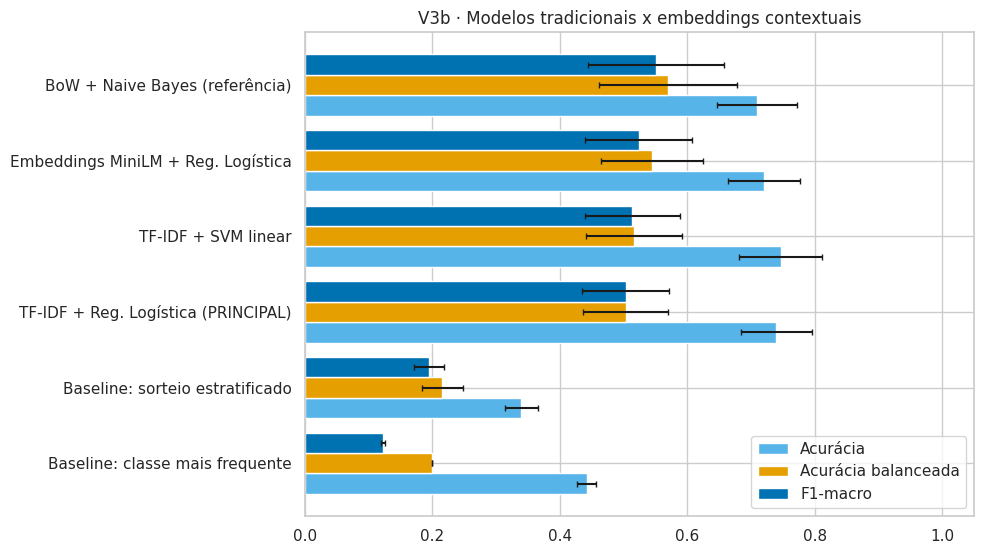

,modelo,acuracia,acuracia_balanceada,f1_macro
0,BoW + Naive Bayes (referência),0.710 ± 0.063,0.570 ± 0.109,0.551 ± 0.107
1,Embeddings MiniLM + Reg. Logística,0.720 ± 0.057,0.544 ± 0.080,0.523 ± 0.084
2,TF-IDF + SVM linear,0.747 ± 0.065,0.516 ± 0.075,0.514 ± 0.074
3,TF-IDF + Reg. Logística (PRINCIPAL),0.740 ± 0.056,0.503 ± 0.066,0.503 ± 0.069
4,Baseline: sorteio estratificado,0.340 ± 0.027,0.215 ± 0.033,0.194 ± 0.024
5,Baseline: classe mais frequente,0.442 ± 0.015,0.200 ± 0.000,0.123 ± 0.003


In [36]:
resultados_final = dict(resultados)
if emb is not None:
    modelo_emb = make_pipeline(LogisticRegression(C=10, class_weight="balanced", max_iter=3000))
    resultados_final["Embeddings MiniLM + Reg. Logística"] = avaliar(modelo_emb, emb, y, cv)
    plot_modelos(resultados_final, "v3b_comparacao_com_embeddings", "V3b · Modelos tradicionais x embeddings contextuais")
    display(tabela(resultados_final))
else:
    print("Sem embeddings: comparação final = tabela da Etapa 4.")

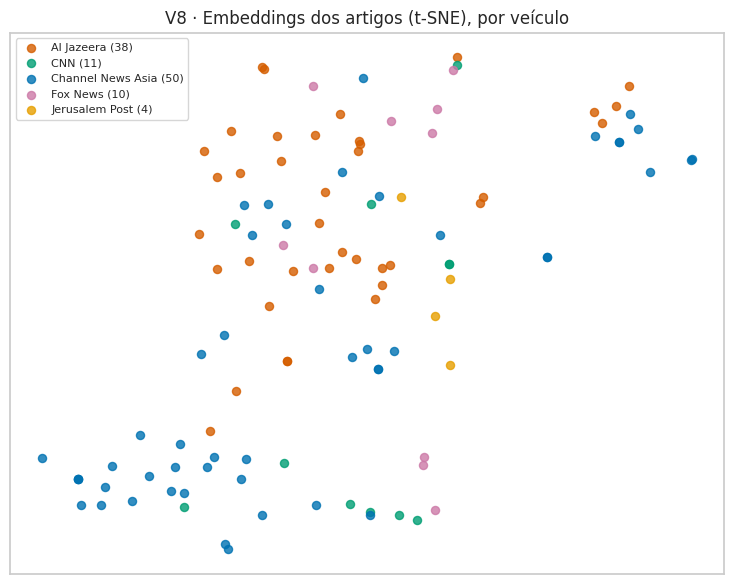

Âncora: Oil prices climb over 2% after strikes on Saudi pipeline and ships in Middle Eas [Channel News Asia]
  sim=0.86 [Channel News Asia] Oil prices rise as latest fighting resurrects Middle East supply disruption risk
  sim=0.84 [Channel News Asia] Oil heads for weekly gain as US-Iran fighting resumes; diesel hits record high
  sim=0.84 [Channel News Asia] Oil prices set for weekly gain as US-Iran hostilities intensify


In [37]:
# VISUALIZAÇÃO 8 — projeção 2D dos embeddings (t-SNE) colorida por veículo
if emb is not None:
    perp = max(2, min(30, (len(df) - 1) // 3))
    p2 = TSNE(n_components=2, perplexity=perp, init="pca", random_state=SEED).fit_transform(emb)
    fig, ax = plt.subplots(figsize=(7.5, 6))
    for c in classes:
        m = y == c
        ax.scatter(p2[m, 0], p2[m, 1], s=34, alpha=0.8, color=cor[c], label=f"{c} ({m.sum()})")
    ax.legend(fontsize=8, loc="best"); ax.set_title("V8 · Embeddings dos artigos (t-SNE), por veículo")
    ax.set_xticks([]); ax.set_yticks([])
    salvar("v8_tsne_embeddings"); plt.show()

    # busca semântica: artigos mais parecidos com um artigo-âncora
    ancora = int(np.argmax(confianca))
    sims = emb @ emb[ancora]; viz = np.argsort(-sims)[1:4]
    print("Âncora:", str(df.loc[ancora, "titulo"])[:80], f"[{y[ancora]}]")
    for j in viz: print(f"  sim={sims[j]:.2f} [{y[j]}] {str(df.loc[j, 'titulo'])[:80]}")

K-Means nos embeddings -> ARI: 0.149 | NMI: 0.267 (TF-IDF/LSA: ARI 0.12 )


,hit@1,hit@5,MRR
TF-IDF unigramas,0.770,0.982,0.860
TF-IDF uni+bigramas,0.752,0.982,0.850
Embeddings MiniLM,0.761,0.982,0.855


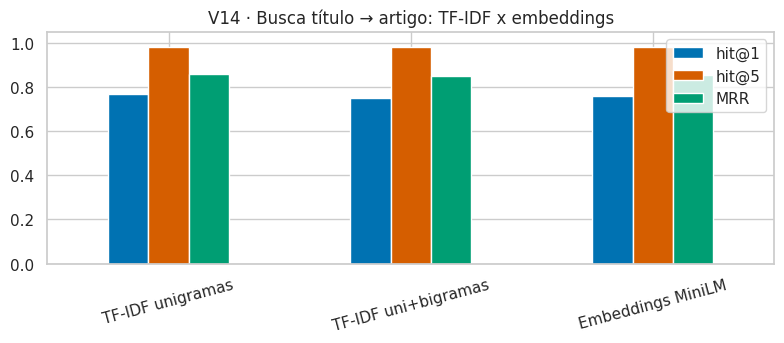

In [38]:
# Embeddings também para (a) agrupamento e (b) busca título -> artigo, comparando com TF-IDF
if emb is not None:
    km_e = KMeans(n_clusters=K_REF, n_init=10, random_state=SEED).fit(emb)
    res_cluster["ARI_vs_veiculo_embeddings"] = round(adjusted_rand_score(y, km_e.labels_), 3)
    res_cluster["NMI_vs_veiculo_embeddings"] = round(normalized_mutual_info_score(y, km_e.labels_), 3)
    print("K-Means nos embeddings -> ARI:", res_cluster["ARI_vs_veiculo_embeddings"], "| NMI:", res_cluster["NMI_vs_veiculo_embeddings"],
          "(TF-IDF/LSA: ARI", res_cluster["ARI_vs_veiculo"], ")")

    Qe = encoder.encode(consultas, normalize_embeddings=True)
    res_busca["Embeddings MiniLM"] = avaliar_busca(Qe @ emb.T)
    tab_busca = pd.DataFrame(res_busca).T.round(3); display(tab_busca)
    ax = tab_busca.plot(kind="bar", figsize=(8, 3.6), color=[PALETA[0], PALETA[1], PALETA[2]], rot=15)
    ax.set_ylim(0, 1.05); ax.set_title("V14 · Busca título → artigo: TF-IDF x embeddings"); salvar("v14_busca_tfidf_vs_embeddings"); plt.show()

In [39]:
# Sumarização: um artigo "típico" (tamanho mais próximo da mediana) por veículo
LEXICO = [r"genocid\w*", r"terror\w*", r"massacre\w*", r"war crime\w*", r"occupation|occupied", r"atrocit\w*", r"apartheid",
          r"militant\w*", r"extremis\w*", r"self-defen[cs]e", r"slaughter\w*", r"aggress\w*"]
RE_LEX = re.compile("|".join(LEXICO), flags=re.I)
def n_lex(t): return len(RE_LEX.findall(t))

resumos = None
if HF_OK:
    try:
        import torch
        from transformers import AutoTokenizer, AutoModelForSeq2SeqLM   # sem pipeline(): as tarefas "summarization"/"text2text" foram removidas das versões novas
        tok_s = AutoTokenizer.from_pretrained("sshleifer/distilbart-cnn-12-6")
        mod_s = AutoModelForSeq2SeqLM.from_pretrained("sshleifer/distilbart-cnn-12-6").eval()
        def sumarizador(txt, **kw):
            enc = tok_s(txt, return_tensors="pt", truncation=True, max_length=1024)
            with torch.no_grad():
                out = mod_s.generate(**enc, max_new_tokens=110, min_length=40, num_beams=4, do_sample=False)
            return [{"summary_text": tok_s.decode(out[0], skip_special_tokens=True)}]
        linhas = []
        for c in classes:
            sub = df[(df[ALVO] == c) & (df["num_palavras"] >= 150)]
            if sub.empty: continue
            i = (sub["num_palavras"] - sub["num_palavras"].median()).abs().idxmin()
            entrada = " ".join(df.loc[i, "texto_masc"].split()[:600])
            s = sumarizador(entrada, max_length=110, min_length=40, do_sample=False, truncation=True)[0]["summary_text"]
            linhas.append({"classe": c, "titulo": str(df.loc[i, "titulo"])[:60], "palavras_orig": len(entrada.split()),
                           "termos_carregados_orig": n_lex(entrada), "palavras_resumo": len(s.split()),
                           "termos_carregados_resumo": n_lex(s), "resumo": s})
        resumos = pd.DataFrame(linhas)
        display(resumos.drop(columns="resumo"))
        for _, r in resumos.iterrows(): print(f"\n[{r['classe']}] {r['resumo']}")
    except Exception as e:
        print("Sumarização indisponível:", repr(e)[:200])
else:
    print("Sumarização ignorada (Hugging Face indisponível).")

config.json:   0%|          | 0.00/1.80k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.22GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

... (3 outputs left out)

Loading weights:   0%|          | 0/358 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=110) and `max_length`(=142) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=110) and `max_length`(=142) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=110) and `max_length`(=142) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=110) and `max_length`(=142) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

,classe,titulo,palavras_orig,termos_carregados_orig,palavras_resumo,termos_carregados_resumo
0,Al Jazeera,"UK charities, protest groups condemn Israeli b...",600,8,45,0
1,CNN,"Ed Sheeran tour: Macklemore dropped, other ope...",600,2,71,0
2,Channel News Asia,Oil rallies for the week as US-Iran fighting r...,600,0,68,0
3,Fox News,"Abdul El-Sayed hits back at Israel questions, ...",600,0,61,0
4,Jerusalem Post,Netanyahu's New York UN visit sees unusual Sec...,343,0,58,0



[Al Jazeera]  UK charities, protest groups condemn Israeli ban threat after sanctions . Israel had warned UK of 'consequences' for sanctions against UK aid groups . Letter recommends employees and activists barred from entering Israel after UK ban on imports from illegal settlements in West Bank .

[CNN]  Rapper Macklemore has been dropped from Ed Sheeran's US tour for his onstage support of Palestine . The rapper made pro-Palestinian remarks during shows in New Jersey earlier this month . On Monday, Robert Kraft, the billionaire owner of the New England Patriots, said he would bar him from performing at Gillette Stadium in Massachusetts . All of the British singer's other openers quit the tour to protest the removal .

[Channel News Asia]  Brent crude futures settled at $96.28 a barrel, up 76 cents, or 0.8 per cent . West Texas Intermediate crude futures finished at $91.48 a barrel . For the week, Brent crude rose 7.6 per cent while U.S. crude gained nearly 10 per cent as supply rout

**Como interpretar (preencher no relatório):** compare, por veículo, a **densidade** de termos carregados no texto original e no
resumo. Se o resumo tende a perdê-los, a sumarização automática **neutraliza o enquadramento** — um cuidado importante para
quem usa IA generativa para "ler" a imprensa. Resumos de modelo pré-treinado também podem introduzir erros factuais:
por isso este componente é **apenas ilustrativo e posterior** à análise tradicional.

### 6.3 RAG: recuperação + geração (FLAN-T5), avaliado como na disciplina
Fluxo da aula: **pergunta → busca de trechos → contexto no prompt → LLM responde**. Como o LLM não é treinado no nosso corpus, o RAG fornece as evidências.
Usamos os três testes pedidos nos slides da aula:
1. **Perguntas com resposta no corpus:** o trecho certo foi recuperado e a resposta respeita a evidência?
2. **Pergunta sem resposta no corpus:** o sistema **admite** que não sabe ou inventa? (há também um limiar de similaridade, apenas uma heurística)
3. **Com × sem RAG**, comparando **com o texto original** (fidelidade > fluência), e variando o top-k.

A coluna `sustentada_no_corpus` fica **vazia de propósito**: é a avaliação humana que você preenche lendo o trecho recuperado.

In [40]:
def blocos(texto, tam=100, maximo=None):
    p = texto.split(); b = [" ".join(p[i:i + tam]) for i in range(0, len(p), tam)]
    return (b[:maximo] if maximo else b) or [""]

rag_trechos, rag_dono = [], []
for i, t in enumerate(df["texto_masc"]):
    for b in blocos(t, 100):
        rag_trechos.append(b); rag_dono.append(i)
rag_dono = np.array(rag_dono)
vec_rag = TfidfVectorizer(ngram_range=(1, 2), strip_accents="unicode", sublinear_tf=True).fit(rag_trechos)
X_rag = vec_rag.transform(rag_trechos)
E_rag = encoder.encode(rag_trechos, batch_size=64, show_progress_bar=False, normalize_embeddings=True) if HF_OK else None
print("Trechos indexados:", len(rag_trechos))

def recuperar(pergunta, top_k=3, metodo="emb"):
    if metodo == "emb" and E_rag is not None:
        s = E_rag @ encoder.encode([pergunta], normalize_embeddings=True)[0]
    else:
        s = cosine_similarity(vec_rag.transform([pergunta]), X_rag).ravel()
    idx = np.argsort(-s)[:top_k]
    return pd.DataFrame({"veiculo": y[rag_dono[idx]], "titulo": df["titulo"].iloc[rag_dono[idx]].astype(str).str[:60].values,
                         "trecho": [rag_trechos[i] for i in idx], "sim": s[idx]})

# teste de sanidade da recuperação (sem LLM): o que o TF-IDF devolve para uma pergunta?
display(recuperar("Who is accused of committing war crimes?", 3, "tfidf")[["veiculo", "titulo", "sim"]].round(3))

Trechos indexados: 854


,veiculo,titulo,sim
0,Channel News Asia,"6 charged over prohibited processions, public ...",0.164
1,Channel News Asia,"6 charged over prohibited processions, public ...",0.128
2,Channel News Asia,"6 charged over prohibited processions, public ...",0.117


In [41]:
RAG_OK = False
if HF_OK:
    try:
        import torch
        from transformers import AutoTokenizer, AutoModelForSeq2SeqLM   # sem pipeline(): a tarefa "text2text-generation" foi removida das versões novas
        tok_g = AutoTokenizer.from_pretrained("google/flan-t5-base")
        mod_g = AutoModelForSeq2SeqLM.from_pretrained("google/flan-t5-base").eval()
        def gerador(prompt, max_new_tokens=80, do_sample=False):
            enc = tok_g(prompt, return_tensors="pt", truncation=True, max_length=512)
            with torch.no_grad():
                out = mod_g.generate(**enc, max_new_tokens=max_new_tokens, do_sample=do_sample)
            return [{"generated_text": tok_g.decode(out[0], skip_special_tokens=True)}]
        RAG_OK = True
    except Exception as e:
        print("Gerador FLAN-T5 indisponível:", repr(e)[:200])

LIMIAR_SIM = 0.25   # abaixo disso o sistema se abstém (heurística para embeddings; ajuste olhando as similaridades das perguntas sem resposta)
def gerar(prompt): return gerador(prompt, max_new_tokens=80, do_sample=False)[0]["generated_text"].strip()

def perguntar(pergunta, modo, top_k=3):
    if modo == "sem RAG":
        return gerar(f"Answer briefly: {pergunta}"), None
    docs = recuperar(pergunta, top_k)
    if docs["sim"].max() < (LIMIAR_SIM if E_rag is not None else 0.05):   # TF-IDF tem escala de similaridade bem menor
        return "I don't know (no evidence retrieved)", docs
    ctx = "\n".join(f"[{r.veiculo}] {r.trecho}" for r in docs.itertuples())
    return gerar("Answer the question using only the context. If the context is not enough, answer 'I don't know'.\n"
                 f"Context:\n{ctx}\nQuestion: {pergunta}\nAnswer:"), docs

PERGUNTAS_RAG = [("com resposta", "Who did the Israel Defense Forces capture in a raid in Gaza?"),
                 ("com resposta", "Why did oil prices climb after strikes in the Middle East?"),
                 ("sem resposta", "What is the population of Brazil?")]
df_rag = None
if RAG_OK:
    linhas = []
    for tipo, q in PERGUNTAS_RAG:
        for modo, k in [("sem RAG", 0), ("RAG top-1", 1), ("RAG top-3", 3)]:
            r, docs = perguntar(q, "sem RAG" if k == 0 else "RAG", max(k, 1))
            linhas.append({"tipo": tipo, "pergunta": q, "configuracao": modo, "resposta": r,
                           "maior_sim": round(float(docs["sim"].max()), 3) if docs is not None else np.nan,
                           "trecho_recuperado": (f"[{docs.veiculo.iloc[0]}] " + docs.trecho.iloc[0][:140]) if docs is not None else "",
                           "abstencao": ("don't know" in r.lower()) or ("unknown" in r.lower()), "sustentada_no_corpus": ""})
    df_rag = pd.DataFrame(linhas)
    for q in [q for _, q in PERGUNTAS_RAG]:
        print("\n>>", q); display(df_rag[df_rag.pergunta == q][["configuracao", "resposta", "maior_sim", "abstencao"]].reset_index(drop=True))
else:
    print("RAG ignorado (sem FLAN-T5 neste ambiente).")

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

... (7 outputs left out)


>> Why did oil prices climb after strikes in the Middle East?


,configuracao,resposta,maior_sim,abstencao
0,sem RAG,The Middle East was a hotbed of economic activity,NaN,False
1,RAG top-1,I don't know,0.671,True
2,RAG top-3,Iran vowed to strike energy infrastructure acr...,0.671,False



>> What is the population of Brazil?


,configuracao,resposta,maior_sim,abstencao
0,sem RAG,"87,069",NaN,False
1,RAG top-1,I don't know,0.341,True
2,RAG top-3,I don't know,0.341,True


**Como interpretar (preencher no relatório):** (i) a recuperação trouxe o veículo/trecho esperado? (ii) a resposta **com RAG** está no texto recuperado ou o modelo ignorou o contexto?
(iii) na pergunta **sem resposta**, o sistema se absteve? (iv) o top-3 melhora ou só adiciona ruído de outros veículos? Uma resposta longa e convincente não é necessariamente correta:
o critério principal é a **fidelidade ao corpus**. Preencha `sustentada_no_corpus` em `resultados/rag_com_e_sem_contexto.csv` lendo o trecho recuperado.

In [43]:
import shutil
from google.colab import files
shutil.make_archive("resultados", "zip", "resultados")
files.download("resultados.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Fechamento — salvando os resultados para o relatório e os slides

In [42]:
def limpo(d): return {k: {m: [round(float(a), 4), round(float(b), 4)] for m, (a, b) in v.items()} for k, v in d.items()}

saida = {
    "fonte_dados": FONTE, "n_artigos": int(len(df)), "n_classes": int(len(classes)), "classes": {k: int(v) for k, v in contagem.items()},
    "classes_removidas": {k: int(v) for k, v in removidas.items()}, "razao_maior_menor_classe": round(float(razao), 2),
    "folds": n_splits, "repeticoes": 5,
    "modelos": limpo(resultados_final), "grupo": limpo(res_grupo) if res_grupo else None,
    "vazamento_nomes": limpo(res_vaz),
    "taxa_erro_principal": round(float(df_pred["erro"].mean()), 4),
    "termos_por_classe": {c: [t for t, _ in l] for c, l in tops.items()},
    "hf_disponivel": bool(HF_OK),
    "holdout": {k: round(float(v), 4) for k, v in res_holdout.items()}, "melhor_C": busca.best_params_["logisticregression__C"],
    "agrupamento": res_cluster, "busca_titulo_artigo": tab_busca.to_dict(), "tom_por_lado": tab_tom.reset_index().to_dict("records"),
    "agencia_acerto_gabarito": {"agente": round(float(acc_ag), 3), "paciente": round(float(acc_pa), 3)},
}
(RES / "metricas.json").write_text(json.dumps(saida, ensure_ascii=False, indent=2), encoding="utf-8")
tab_modelos.to_csv(RES / "tabela_modelos.csv", index=False)
rel.to_csv(RES / "relatorio_classificacao_principal.csv")
erros.to_csv(RES / "erros_modelo_principal.csv", index=False)
if resumos is not None: resumos.to_csv(RES / "resumos_por_veiculo.csv", index=False)
if df_rag is not None: df_rag.to_csv(RES / "rag_com_e_sem_contexto.csv", index=False)
tab_classe.to_csv(RES / "metricas_por_classe_holdout.csv", index=False); tab_papeis.to_csv(RES / "agencia_por_veiculo.csv", index=False); tab_tom.to_csv(RES / "tom_por_lado.csv")

print("Arquivos em", RES.resolve()); print(*sorted(p.name for p in RES.rglob('*') if p.is_file()), sep="\n  ")
print("\nPrincipais números para o relatório/slides:")
print(json.dumps({k: saida[k] for k in ["fonte_dados", "n_artigos", "n_classes", "classes", "taxa_erro_principal"]}, ensure_ascii=False, indent=1))

Arquivos em /content/resultados
agencia_por_veiculo.csv
  erros_modelo_principal.csv
  metricas.json
  metricas_por_classe_holdout.csv
  rag_com_e_sem_contexto.csv
  relatorio_classificacao_principal.csv
  resumos_por_veiculo.csv
  tabela_modelos.csv
  tom_por_lado.csv
  v11_clusters_vs_veiculos.png
  v12_tom_por_lado.png
  v13_agencia_por_lado.png
  v14_busca_tfidf_vs_embeddings.png
  v1_v2_classes_e_tamanho.png
  v3_comparacao_modelos.png
  v3b_comparacao_com_embeddings.png
  v4_matriz_confusao.png
  v5_termos_por_classe.png
  v6_vazamento_nomes.png
  v7_similaridade_veiculos.png
  v8_tsne_embeddings.png
  v9_v10_agrupamento.png

Principais números para o relatório/slides:
{
 "fonte_dados": "corpus T1",
 "n_artigos": 113,
 "n_classes": 5,
 "classes": {
  "Channel News Asia": 50,
  "Al Jazeera": 38,
  "CNN": 11,
  "Fox News": 10,
  "Jerusalem Post": 4
 },
 "taxa_erro_principal": 0.2743
}
